# Practical Assignment 6: Clustering Algorithms
### Mandi Market Segmentation for Food Inflation Prediction

| | |
|---|---|
| **Name** | Tushar Kaldate |
| **Roll No.** | 47 |
| **Batch** | A2 |
| **PRN** | 202401040191 |
| **GitHub Repo** | [github.com/tusharkkp/AI-ML](https://github.com/tusharkkp/AI-ML/) |
| **Selected Instance** | Food Inflation Prediction (*Food Inflation Prediction and Household Affordability Monitoring System*) |

## 1. Title
**Implementing and Evaluating Clustering Algorithms (K-Means, Hierarchical, DBSCAN, Gaussian Mixture) to Segment Maharashtra Wholesale Mandis by Onion and Tomato Price Behaviour**

## 2. Aim
To implement clustering algorithms on a real-world food price dataset and identify meaningful groups of wholesale markets (mandis) that behave similarly in terms of price level, volatility, arrivals and seasonality, and to evaluate the quality of the clusters with the **Silhouette score**, **Davies-Bouldin index**, **Calinski-Harabasz index** and **visual inspection**.

## 3. Experiment Objectives
1. To understand unsupervised learning and the role of clustering in discovering hidden structure in unlabeled data.
2. To engineer market-level behavioural features from raw daily mandi price and arrival records.
3. To implement **K-Means**, **Agglomerative (Hierarchical) clustering**, **DBSCAN** and **Gaussian Mixture Models**.
4. To select the number of clusters using the elbow method, silhouette analysis and the Davies-Bouldin index.
5. To compare algorithms using internal validation metrics and visualise clusters with PCA.
6. To interpret the clusters in the context of food inflation and household affordability.

## 4. Experiment Outcome
After completing this experiment, the student will be able to:
- Apply K-Means, hierarchical, density-based and model-based clustering on a real-world dataset.
- Prepare data for clustering (cleaning, feature engineering, scaling).
- Evaluate clustering quality with silhouette score, Davies-Bouldin index and visual inspection.
- Interpret the discovered clusters and relate them to a practical problem (food price risk monitoring).

## 5. Conceptual Details

**Clustering** is an *unsupervised* learning task: there are no target labels, and the algorithm groups data points so that points in the same cluster are more similar to each other than to those in other clusters.

| Algorithm | Idea | Strengths | Weaknesses |
|---|---|---|---|
| **K-Means** | Partitions data into *k* clusters by repeatedly assigning each point to the nearest centroid and recomputing centroids, minimising within-cluster sum of squares (inertia). | Fast, simple, scalable | Needs *k* in advance; assumes round clusters; sensitive to outliers |
| **Agglomerative (Hierarchical)** | Starts with every point as its own cluster and repeatedly merges the closest pair (Ward linkage minimises the increase in variance). Result is a dendrogram. | No need to fix *k* beforehand; dendrogram is interpretable | Slow on huge data; merges cannot be undone |
| **DBSCAN** | Groups points that are densely packed (at least `min_samples` neighbours within radius `eps`) and marks sparse points as **noise**. | Finds arbitrary shapes; detects outliers; no *k* needed | Sensitive to `eps`; struggles with varying density |
| **Gaussian Mixture (GMM)** | Assumes data comes from a mixture of Gaussians and fits them with Expectation-Maximisation, giving soft (probabilistic) assignments. | Elliptical clusters; soft assignments | Assumes Gaussian shapes; can overfit |

**Why scaling is mandatory:** clustering uses distances, so features with large numeric ranges would dominate. We apply `StandardScaler` (zero mean, unit variance).

**Internal validation metrics** (no ground-truth labels are available):
- **Silhouette score** `s = (b - a) / max(a, b)` where *a* is the mean intra-cluster distance and *b* the mean nearest-cluster distance. Range [-1, 1]; **higher is better**.
- **Davies-Bouldin index** = average similarity between each cluster and its most similar cluster (ratio of within-cluster scatter to between-cluster separation). **Lower is better** (0 is best).
- **Calinski-Harabasz index** = ratio of between-cluster to within-cluster dispersion. **Higher is better**.
- **Elbow method** looks for the *k* where inertia stops dropping sharply.
- **PCA projection** squeezes the features into 2-D so clusters can be inspected visually.

## 6. Data Gathering and Position in the ML Project
This notebook is the **next step of the ML project *"Food Inflation Prediction and Household Affordability Monitoring System"***. In the previous step I identified, evaluated and ranked about ten candidate data sources (documented in `source_inventory.md`) and then collected the following datasets from official and open sources:

| Dataset | Source | Content |
|---|---|---|
| `cpi_data.csv` | MoSPI Consumer Price Index API | Monthly food CPI index and YoY inflation, All-India and Maharashtra |
| `wholesale_prices.csv` | Agmarknet via data.gov.in API + curated historical Agmarknet archive | Daily mandi min / max / modal prices (Rs/quintal) |
| `market_arrivals.csv` | Agmarknet mandi arrivals | Daily arrival quantity (tonnes) per mandi |
| `retail_prices.csv` | DCA Price Monitoring System bulletin | Retail prices of 22 essential commodities |
| `household_expenditure.csv` | MoSPI HCES 2022-23 factsheets | Household spending (MPCE) and food budget shares |
| `model_ready_pune_tomato.csv` | Derived from the above | Lag / rolling features for forecasting Pune tomato prices |

The raw data was then cleaned, standardised (commodity names, units, anomaly flags) and saved as the CSV files used here. **Pipeline so far:**
`Source identification -> Data collection and cleaning -> (this notebook) Exploratory unsupervised learning (clustering) -> Supervised forecasting models (regression / time-series) -> Affordability monitoring dashboard`.

**Why clustering here?** Food inflation in India is strongly driven by vegetables such as onion and tomato, and different mandis react very differently to supply shocks. Grouping mandis by price behaviour will tell us which markets are *stable*, which are *volatile*, and which act as *price-setting hubs*. These groups can later be used as a categorical feature, or to train separate forecasting models per cluster.

## 7. Algorithm / Flowchart

```text
 +---------------------------------------------+
 | START: load wholesale_prices + market_arrivals |
 +---------------------------------------------+
                      |
                      v
 +---------------------------------------------+
 | Filter: Maharashtra, Onion & Tomato          |
 | Clean: drop missing / non-positive prices,   |
 | remove extreme data-entry outliers           |
 +---------------------------------------------+
                      |
                      v
 +---------------------------------------------+
 | Aggregate to daily (market, commodity) series|
 | and merge arrival quantities                 |
 +---------------------------------------------+
                      |
                      v
 +---------------------------------------------+
 | Feature engineering per (market, commodity): |
 | price level, volatility, price range ratio,  |
 | spread, arrivals, monsoon uplift,            |
 | price-arrival correlation                    |
 +---------------------------------------------+
                      |
                      v
 +---------------------------------------------+
 | Standardise features (StandardScaler)        |
 +---------------------------------------------+
                      |
                      v
 +---------------------------------------------+
 | Choose k: elbow + silhouette + Davies-Bouldin|
 +---------------------------------------------+
                      |
          +-----------+-----------+-----------+
          v           v           v           v
      K-Means    Agglomerative   DBSCAN       GMM
          \           |           |           /
           +-----------+-----------+----------+
                      |
                      v
 +---------------------------------------------+
 | Evaluate: Silhouette, Davies-Bouldin,        |
 | Calinski-Harabasz                            |
 +---------------------------------------------+
                      |
                      v
 +---------------------------------------------+
 | Visualise (PCA), profile clusters, interpret |
 +---------------------------------------------+
                      |
                      v
                    END
```

**K-Means steps:** (1) choose *k*; (2) initialise centroids (k-means++); (3) assign each point to its nearest centroid; (4) recompute centroids as cluster means; (5) repeat 3-4 until assignments stop changing.

## 8. Python Code

### 8.1 Import libraries

In [1]:
# ---- Core libraries ----
import os
import warnings
import numpy as np
import pandas as pd

# ---- Visualisation ----
import matplotlib.pyplot as plt
import seaborn as sns

# ---- Scikit-learn: preprocessing, clustering, metrics, PCA ----
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score)

# ---- SciPy: dendrogram for hierarchical clustering ----
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")           # keep the output clean
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 47                           # my roll number, for reproducibility
np.random.seed(RANDOM_STATE)

### 8.2 Load the datasets

In [2]:
# Folder containing the CSV files collected in the data-gathering step.
# Change DATA_DIR if your files are stored somewhere else.
DATA_DIR = "."

wholesale = pd.read_csv(os.path.join(DATA_DIR, "wholesale_prices.csv"), parse_dates=["observation_date"])
arrivals  = pd.read_csv(os.path.join(DATA_DIR, "market_arrivals.csv"),  parse_dates=["observation_date"])

print("Wholesale prices :", wholesale.shape)
print("Market arrivals  :", arrivals.shape)
print("Date range       :", wholesale.observation_date.min().date(), "->", wholesale.observation_date.max().date())
wholesale.head()

Wholesale prices : (71307, 14)
Market arrivals  : (66745, 10)
Date range       : 2016-01-01 -> 2026-11-17


,observation_date,commodity_name,raw_commodity_name,variety,state,district,market_name,min_price_rs_per_qtl,max_price_rs_per_qtl,modal_price_rs_per_qtl,price_unit,price_type,is_anomalous_flag,data_source
0,2026-11-17,Absinthe,Absinthe,chirayta,Madhya Pradesh,Neemuch,Neemuch Apmc,3380.00,3561.00,3421.00,Rs/Quintal,Wholesale,False,data.gov.in AGMARKNET API (9ef84268-d588-465a-...
1,2026-11-17,Absinthe,Absinthe,chirayta,Madhya Pradesh,Neemuch,Neemuch Apmc,1500.00,3620.00,3400.00,Rs/Quintal,Wholesale,False,data.gov.in AGMARKNET API (9ef84268-d588-465a-...
2,2026-11-17,Ajwan,Ajwan,Ajwan,Madhya Pradesh,Bhopal,Bhopal Apmc,27094.77,27094.77,27094.77,Rs/Quintal,Wholesale,False,data.gov.in AGMARKNET API (9ef84268-d588-465a-...
3,2026-11-17,Ajwan,Ajwan,Other,Gujarat,Jamnagar,Jamnagar Apmc,12500.00,23300.00,21550.00,Rs/Quintal,Wholesale,False,data.gov.in AGMARKNET API (9ef84268-d588-465a-...
4,2026-11-17,Ajwan,Ajwan,Ajwan,Madhya Pradesh,Ratlam,Jaora Apmc,10000.00,10000.00,10000.00,Rs/Quintal,Wholesale,False,data.gov.in AGMARKNET API (9ef84268-d588-465a-...


### 8.3 Select the study scope and clean the data

In [3]:
# Onion and Tomato are the most volatile food items in the Indian CPI basket,
# and Maharashtra has the densest mandi coverage in our collected data.
STATE = "Maharashtra"
COMMODITIES = ["Onion", "Tomato"]

df = wholesale[(wholesale.state == STATE) & (wholesale.commodity_name.isin(COMMODITIES))].copy()
print("Rows after scope filter       :", len(df))

# 1) Drop rows without a valid modal price (modal price = most common trading price)
df = df.dropna(subset=["modal_price_rs_per_qtl"])
df = df[df.modal_price_rs_per_qtl > 0]

# 2) Remove extreme data-entry errors: prices above 5x the median of that
#    (commodity, market) pair are treated as recording mistakes.
median_price = df.groupby(["commodity_name", "market_name"]).modal_price_rs_per_qtl.transform("median")
before = len(df)
df = df[df.modal_price_rs_per_qtl <= 5 * median_price]
print("Extreme outliers removed      :", before - len(df))
print("Rows after cleaning           :", len(df))

# 3) Several varieties can be traded in one mandi on a day; average them to get
#    one price observation per (date, commodity, market).
daily = (df.groupby(["observation_date", "commodity_name", "market_name"])
           .agg(modal=("modal_price_rs_per_qtl", "mean"),
                pmin=("min_price_rs_per_qtl", "mean"),
                pmax=("max_price_rs_per_qtl", "mean"))
           .reset_index())

# 4) Attach daily arrival quantity (tonnes) for the same mandi and commodity.
arr = (arrivals[(arrivals.state == STATE) & (arrivals.commodity_name.isin(COMMODITIES))]
       .groupby(["observation_date", "commodity_name", "market_name"])
       .arrival_quantity_tonnes.sum().reset_index())
daily = daily.merge(arr, how="left", on=["observation_date", "commodity_name", "market_name"])

# 5) Helper columns used for feature engineering
daily["spread_ratio"] = (daily.pmax - daily.pmin) / daily.modal      # relative min-max spread in a day
daily["is_monsoon"] = daily.observation_date.dt.month.isin([6, 7, 8, 9])   # Jun-Sep

print("Daily observations            :", len(daily))
print("Share with arrival data       : %.1f%%" % (100 * daily.arrival_quantity_tonnes.notna().mean()))
daily.head()

Rows after scope filter       : 63888
Extreme outliers removed      : 744
Rows after cleaning           : 63143
Daily observations            : 62945
Share with arrival data       : 99.9%


,observation_date,commodity_name,market_name,modal,pmin,pmax,arrival_quantity_tonnes,spread_ratio,is_monsoon
0,2016-01-01,Onion,Akluj,2000.0,800.0,2000.0,3.0,0.600000,False
1,2016-01-01,Onion,Amarawati,1550.0,1400.0,1700.0,40.0,0.193548,False
2,2016-01-01,Onion,Barshi,1680.0,100.0,2005.0,43.0,1.133929,False
3,2016-01-01,Onion,Bhivandi,1650.0,1540.0,1950.0,5.0,0.248485,False
4,2016-01-01,Onion,Chandrapur(Ganjwad),1500.0,1000.0,1900.0,25.0,0.600000,False


### 8.4 Feature engineering: one row per (mandi, commodity)
Clustering needs **one feature vector per object being clustered**. Here the object is a *mandi trading one commodity*, and the features summarise how its price behaves over time:

| Feature | Meaning |
|---|---|
| `mean_log_price` | Typical price level (log scale to reduce skew) |
| `cv_price` | Coefficient of variation = std / mean, a volatility measure |
| `log_p95_p5` | Log of 95th / 5th percentile price, measuring extreme swings (spike risk) |
| `mean_spread` | Average daily (max - min) / modal price, i.e. intra-day price dispersion |
| `mean_log_arrival` | Typical market size (log of arrivals in tonnes) |
| `monsoon_uplift` | Mean monsoon price / mean non-monsoon price (seasonality) |
| `price_arrival_corr` | Correlation of price with arrivals (supply sensitivity) |

In [4]:
MIN_OBS = 150   # keep only (mandi, commodity) pairs with enough history to compute stable statistics

def market_features(g):
    """Summarise the price behaviour of one (market, commodity) daily series."""
    monsoon, other = g[g.is_monsoon], g[~g.is_monsoon]
    return pd.Series({
        "n_obs": len(g),
        "mean_log_price": np.log(g.modal).mean(),
        "cv_price": g.modal.std() / g.modal.mean(),
        "log_p95_p5": np.log(g.modal.quantile(0.95) / g.modal.quantile(0.05)),
        "mean_spread": g.spread_ratio.mean(),
        "mean_log_arrival": np.log1p(g.arrival_quantity_tonnes).mean(),
        "monsoon_uplift": monsoon.modal.mean() / other.modal.mean() if len(monsoon) and len(other) else np.nan,
        "price_arrival_corr": g[["modal", "arrival_quantity_tonnes"]].corr().iloc[0, 1],
    })

features = daily.groupby(["commodity_name", "market_name"]).apply(market_features).reset_index()
print("Candidate (market, commodity) pairs:", len(features))

features = features[features.n_obs >= MIN_OBS].dropna().reset_index(drop=True)
print("Pairs kept (>= %d obs, no missing) :" % MIN_OBS, len(features))
print(features.commodity_name.value_counts().to_string())
features.describe().round(3)

Candidate (market, commodity) pairs: 213
Pairs kept (>= 150 obs, no missing) : 109
commodity_name
Onion     67
Tomato    42


,n_obs,mean_log_price,cv_price,log_p95_p5,mean_spread,mean_log_arrival,monsoon_uplift,price_arrival_corr
count,109.000,109.000,109.000,109.000,109.000,109.000,109.000,109.000
mean,547.853,6.746,0.668,1.920,0.784,3.896,1.209,-0.097
std,235.704,0.308,0.111,0.493,0.364,2.074,0.428,0.182
min,160.000,4.739,0.224,0.773,0.174,0.713,0.663,-0.508
25%,325.000,6.668,0.608,1.664,0.537,1.844,0.865,-0.224
50%,578.000,6.750,0.697,1.910,0.757,3.885,0.940,-0.083
75%,740.000,6.836,0.740,2.079,1.031,5.820,1.631,0.025
max,968.000,7.761,0.858,5.262,1.982,7.822,2.109,0.398


### 8.5 Scale the features

Feature matrix shape: (109, 7)


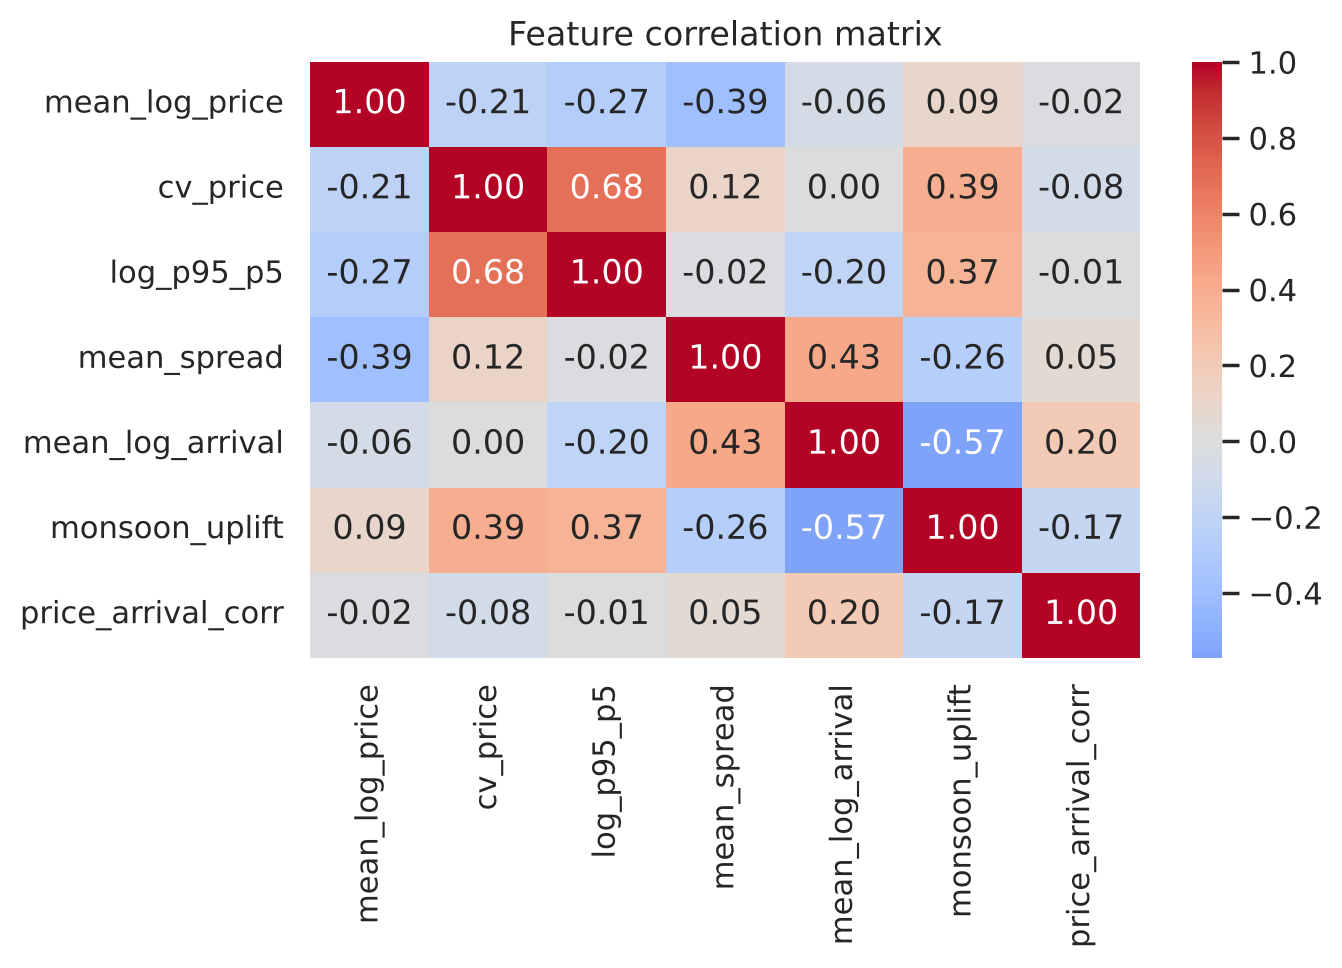

In [5]:
FEATURE_COLS = ["mean_log_price", "cv_price", "log_p95_p5", "mean_spread",
                "mean_log_arrival", "monsoon_uplift", "price_arrival_corr"]

# Winsorising: a few mandis have extreme feature values (e.g. a huge price range ratio) which would
# become tiny single-point clusters. We clip each feature to its 2.5th - 97.5th percentile range
# so that clusters describe the bulk of the markets instead of isolating one or two outliers.
features_w = features.copy()
for col in FEATURE_COLS:
    lo, hi = features[col].quantile([0.025, 0.975])
    features_w[col] = features[col].clip(lo, hi)

# StandardScaler: (x - mean) / std, so every feature contributes equally to distances
scaler = StandardScaler()
X = scaler.fit_transform(features_w[FEATURE_COLS])
print("Feature matrix shape:", X.shape)

# Quick look at feature correlations to spot redundant features
plt.figure(figsize=(7, 5))
sns.heatmap(features[FEATURE_COLS].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.show()

### 8.6 Choosing the number of clusters (k)
We sweep *k* from 2 to 8 and track four indicators: inertia (elbow), silhouette score (higher is better), Davies-Bouldin index (lower is better) and Calinski-Harabasz index (higher is better).

,smallest_cluster,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,,
2,42,544.176,0.291,1.452,43.027
3,20,425.743,0.302,1.232,41.985
4,15,372.353,0.280,1.366,36.720
5,12,338.486,0.224,1.467,32.608
6,10,302.748,0.242,1.330,31.317
7,11,279.065,0.201,1.426,29.480
8,7,261.080,0.207,1.404,27.739


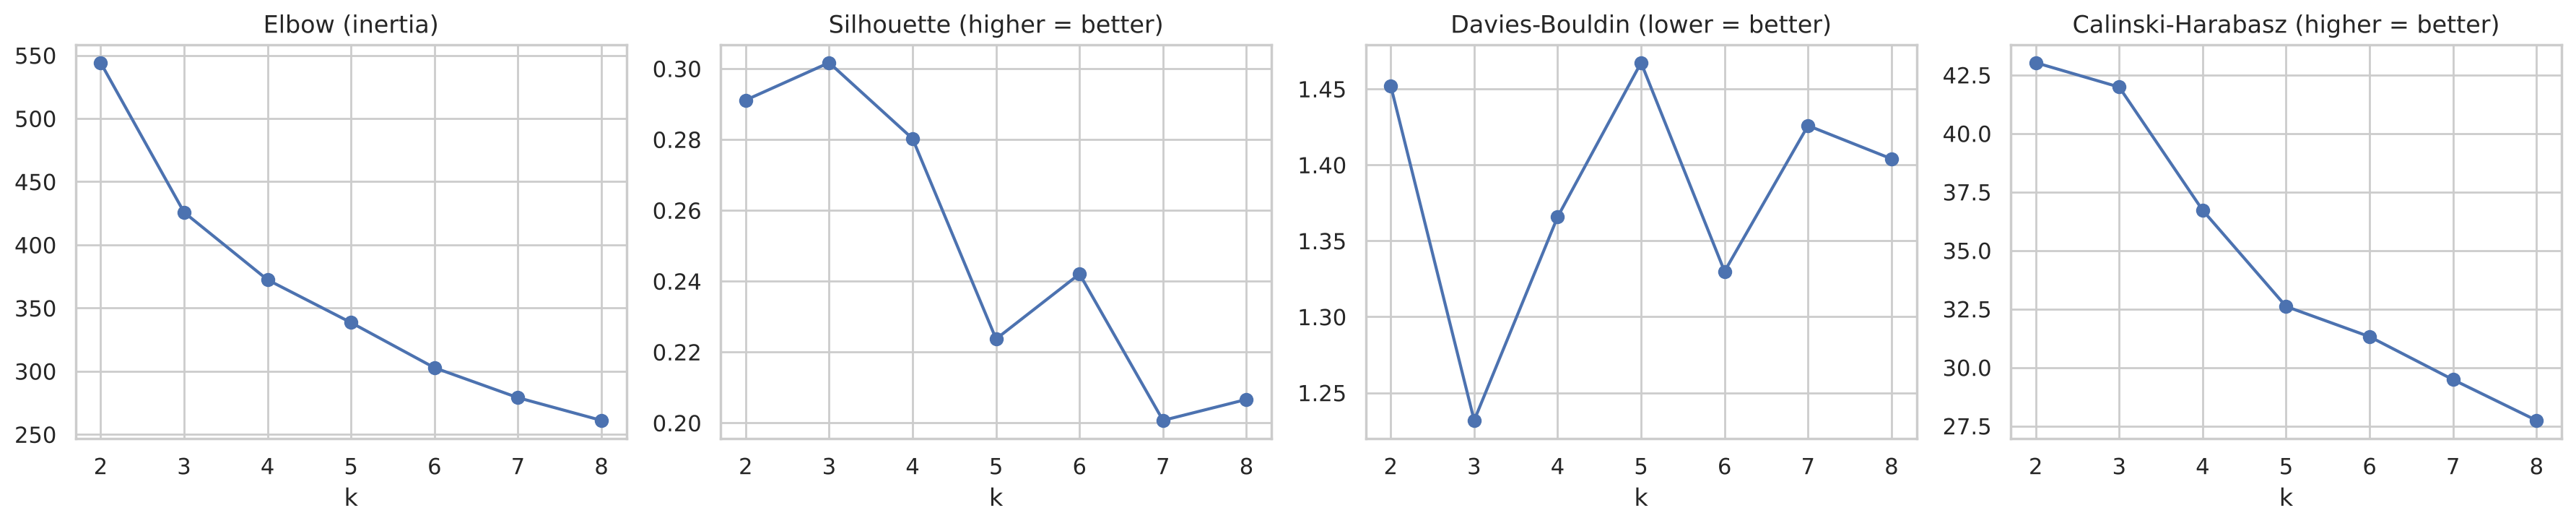

In [6]:
K_RANGE = range(2, 9)
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)   # n_init: restarts to avoid bad centroids
    labels = km.fit_predict(X)
    rows.append({"k": k,
                 "smallest_cluster": int(np.bincount(labels).min()),   # size of the smallest cluster
                 "inertia": km.inertia_,
                 "silhouette": silhouette_score(X, labels),
                 "davies_bouldin": davies_bouldin_score(X, labels),
                 "calinski_harabasz": calinski_harabasz_score(X, labels)})
k_scores = pd.DataFrame(rows).set_index("k")
display(k_scores.round(3))

# Plot the four indicators side by side
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, col, title in zip(axes,
        ["inertia", "silhouette", "davies_bouldin", "calinski_harabasz"],
        ["Elbow (inertia)", "Silhouette (higher = better)", "Davies-Bouldin (lower = better)", "Calinski-Harabasz (higher = better)"]):
    ax.plot(k_scores.index, k_scores[col], marker="o")
    ax.set_title(title); ax.set_xlabel("k")
plt.tight_layout()
plt.show()

In [7]:
# Choose k automatically: highest silhouette score among k = 3..6 whose smallest cluster has at
# least 5 mandi series (~5% of the data). k = 2 is excluded because it is only a trivial split, and
# tiny clusters of 1-2 points are outliers, not meaningful market segments.
MIN_CLUSTER_SIZE = 5
candidates = k_scores.loc[3:6]
candidates = candidates[candidates.smallest_cluster >= MIN_CLUSTER_SIZE]
BEST_K = int(candidates.silhouette.idxmax())
print("Selected k =", BEST_K,
      "| silhouette = %.3f" % k_scores.loc[BEST_K, "silhouette"],
      "| Davies-Bouldin = %.3f" % k_scores.loc[BEST_K, "davies_bouldin"])

Selected k = 3 | silhouette = 0.302 | Davies-Bouldin = 1.232


### 8.7 Algorithm 1: K-Means

In [8]:
kmeans = KMeans(n_clusters=BEST_K, n_init=50, random_state=RANDOM_STATE)
features["kmeans"] = kmeans.fit_predict(X)
print("K-Means cluster sizes:")
print(features.kmeans.value_counts().sort_index().to_string())

K-Means cluster sizes:
kmeans
0    35
1    54
2    20


### 8.8 Algorithm 2: Agglomerative (Hierarchical) clustering
The dendrogram below shows how mandis merge step by step with **Ward linkage**. A horizontal cut through the tallest vertical gaps suggests a natural number of clusters.

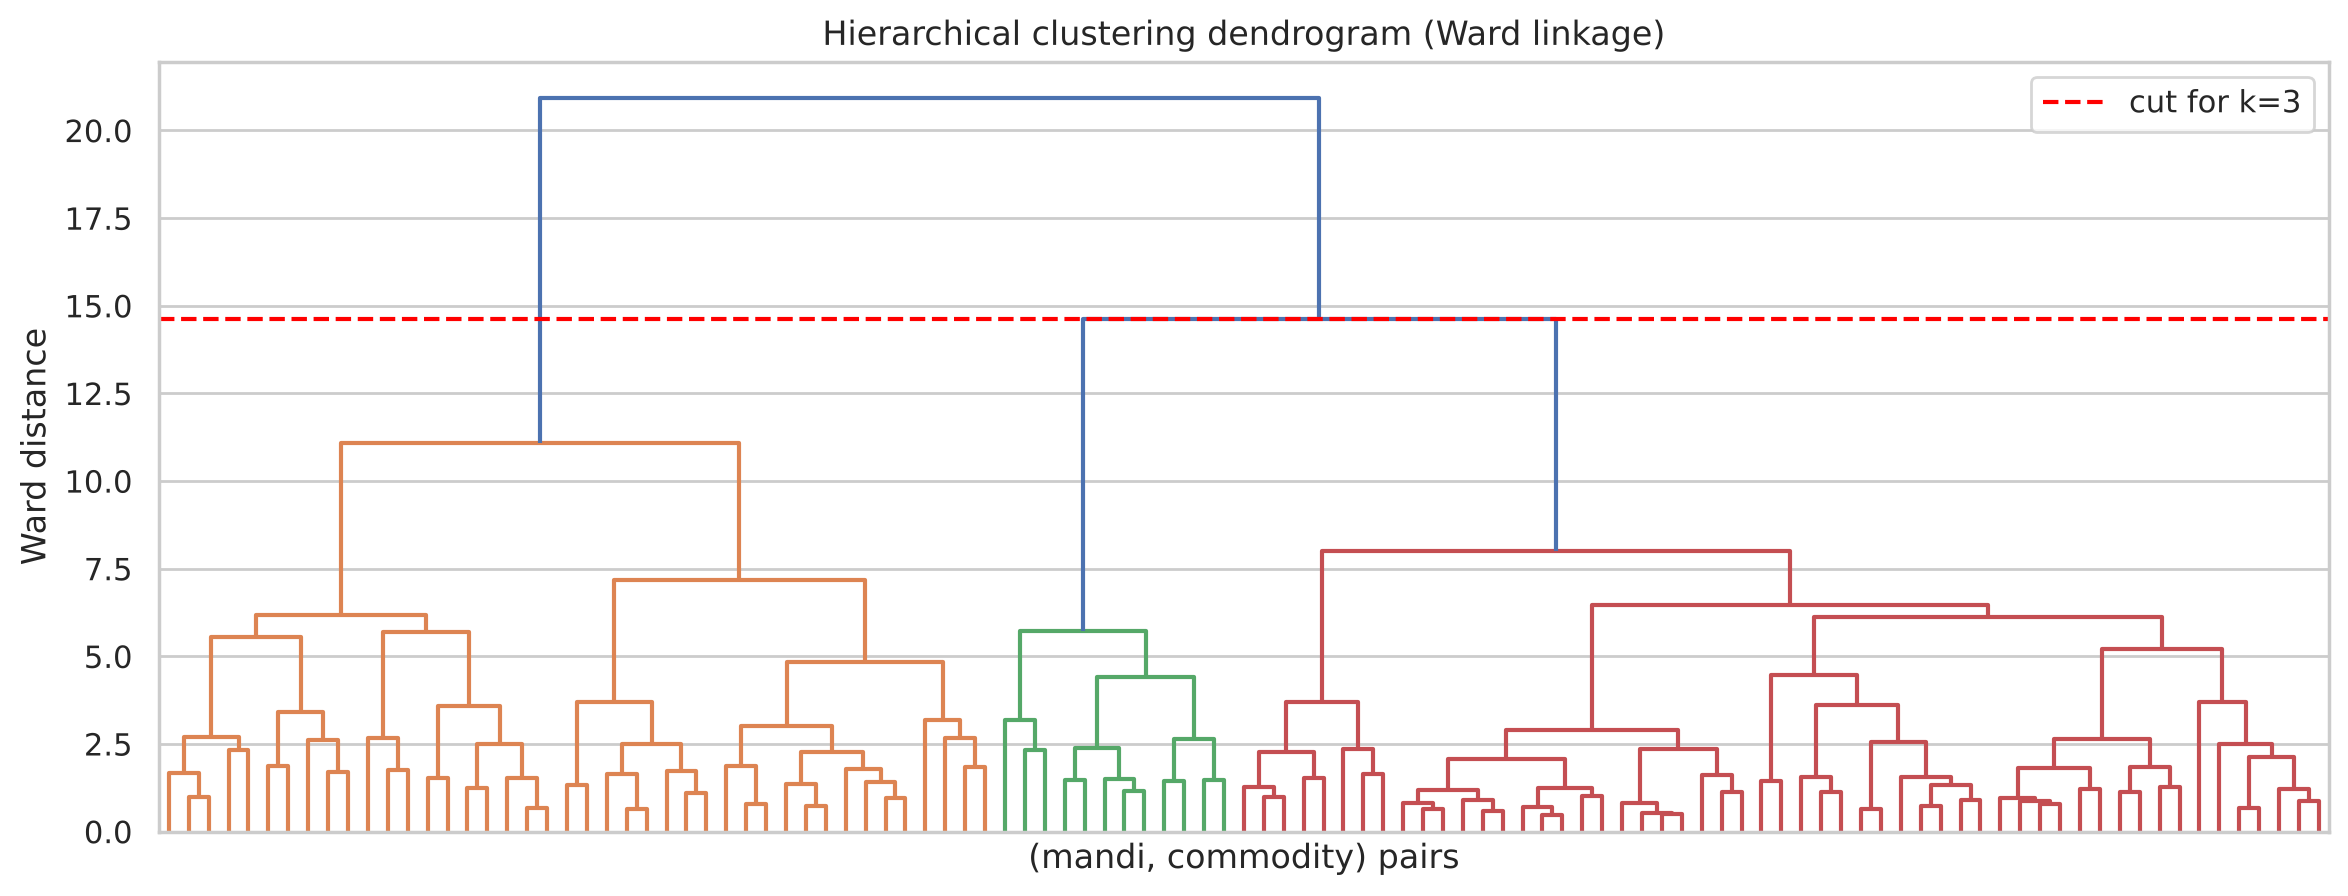

Agglomerative cluster sizes:
agglomerative
0    42
1    55
2    12


In [9]:
# Build the linkage matrix (Ward = merge the pair that least increases within-cluster variance)
Z = linkage(X, method="ward")

plt.figure(figsize=(14, 5))
dendrogram(Z, no_labels=True, color_threshold=Z[-(BEST_K - 1), 2])   # colour branches at the BEST_K cut
plt.axhline(Z[-(BEST_K - 1), 2], color="red", linestyle="--", label=f"cut for k={BEST_K}")
plt.title("Hierarchical clustering dendrogram (Ward linkage)")
plt.xlabel("(mandi, commodity) pairs"); plt.ylabel("Ward distance")
plt.legend(); plt.show()

agg = AgglomerativeClustering(n_clusters=BEST_K, linkage="ward")
features["agglomerative"] = agg.fit_predict(X)
print("Agglomerative cluster sizes:")
print(features.agglomerative.value_counts().sort_index().to_string())

### 8.9 Algorithm 3: DBSCAN
DBSCAN needs `eps` (neighbourhood radius) and `min_samples`. A common heuristic is the **k-distance plot**: sort every point's distance to its k-th nearest neighbour and look for the "knee".

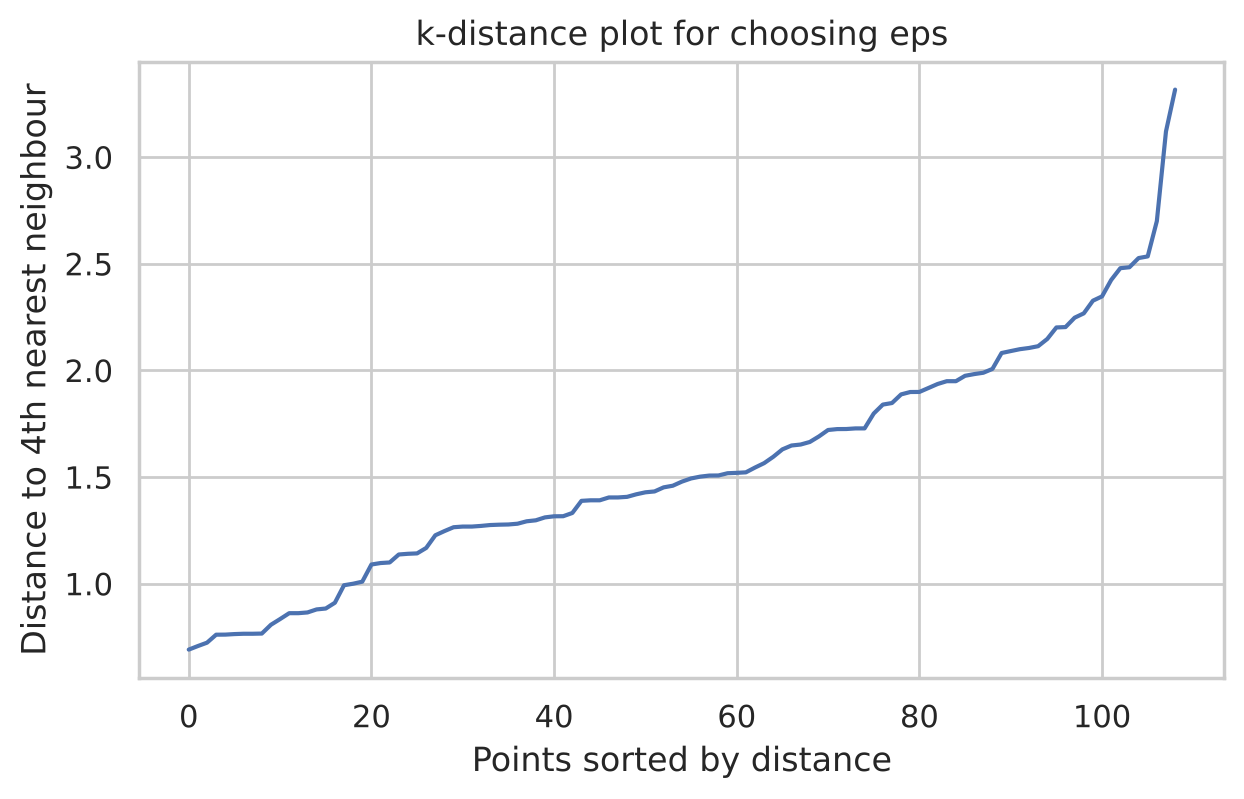

Best eps = 1.60 -> 2 clusters, 27.5% noise, silhouette (non-noise) = 0.392
DBSCAN labels (-1 = noise):
dbscan
-1    30
 0    57
 1    22


In [10]:
MIN_SAMPLES = 4   # roughly 2 x number of dimensions is a common rule; 4 suits our small dataset

# Distance of every point to its MIN_SAMPLES-th nearest neighbour (the point itself counts as the 1st)
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X)
distances, _ = nn.kneighbors(X)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(7, 4))
plt.plot(k_dist)
plt.xlabel("Points sorted by distance"); plt.ylabel(f"Distance to {MIN_SAMPLES}th nearest neighbour")
plt.title("k-distance plot for choosing eps"); plt.show()

# Small grid search over eps. We score only the non-noise points and require 2+ clusters
# with at most 30% of points flagged as noise, so the score is not driven by one big blob.
best = None
for eps in np.arange(0.8, 2.6, 0.1):
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X)
    mask = lab != -1
    n_clusters = len(set(lab[mask]))
    noise_share = 1 - mask.mean()
    if n_clusters >= 2 and noise_share <= 0.30:
        s = silhouette_score(X[mask], lab[mask])
        if best is None or s > best[0]:
            best = (s, eps, n_clusters, noise_share)

if best is None:
    print("No eps satisfied the constraints; falling back to eps = 1.5")
    EPS = 1.5
else:
    EPS = round(best[1], 2)
    print("Best eps = %.2f -> %d clusters, %.1f%% noise, silhouette (non-noise) = %.3f"
          % (EPS, best[2], 100 * best[3], best[0]))

dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)
features["dbscan"] = dbscan.fit_predict(X)          # label -1 means noise / outlier
print("DBSCAN labels (-1 = noise):")
print(features.dbscan.value_counts().sort_index().to_string())

### 8.10 Algorithm 4: Gaussian Mixture Model (GMM)

In [11]:
# Same number of components as K-Means; 'full' covariance lets each cluster be an ellipse
gmm = GaussianMixture(n_components=BEST_K, covariance_type="full", n_init=10, random_state=RANDOM_STATE)
features["gmm"] = gmm.fit_predict(X)
print("GMM cluster sizes:")
print(features.gmm.value_counts().sort_index().to_string())
print("GMM BIC = %.1f (lower is better when comparing models)" % gmm.bic(X))

GMM cluster sizes:
gmm
0    52
1    40
2    17
GMM BIC = 1974.0 (lower is better when comparing models)


### 8.11 Compare the algorithms with internal validation metrics
For DBSCAN the metrics are computed on non-noise points only (noise is not a cluster), and the table also reports how many points were left out.

,Clusters,Noise points,Silhouette,Davies-Bouldin,Calinski-Harabasz
Algorithm,,,,,
K-Means,3,0,0.303,1.235,41.987
Agglomerative (Ward),3,0,0.300,1.226,39.444
DBSCAN,2,30,0.392,1.042,49.332
Gaussian Mixture,3,0,0.296,1.240,40.331


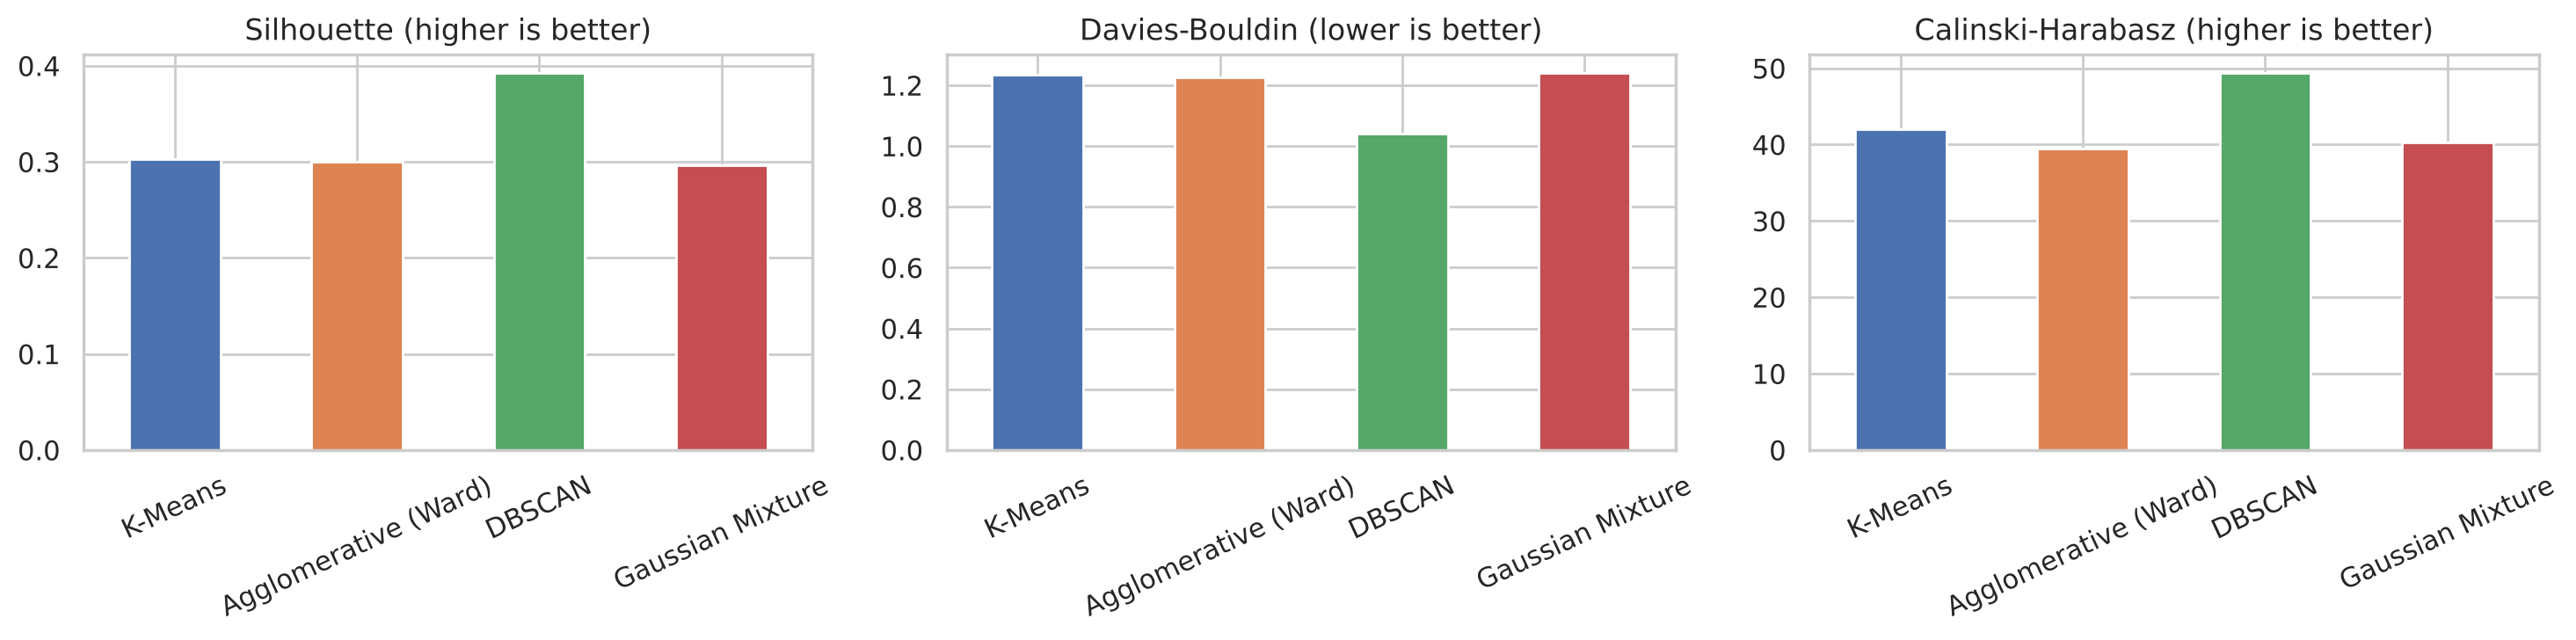

Final model for interpretation: K-Means


In [12]:
def evaluate(name, labels):
    """Return silhouette, Davies-Bouldin and Calinski-Harabasz for a labelling (noise = -1 is excluded)."""
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    if n_clusters < 2:
        return {"Algorithm": name, "Clusters": n_clusters, "Noise points": int((~mask).sum()),
                "Silhouette": np.nan, "Davies-Bouldin": np.nan, "Calinski-Harabasz": np.nan}
    return {"Algorithm": name, "Clusters": n_clusters, "Noise points": int((~mask).sum()),
            "Silhouette": silhouette_score(X[mask], labels[mask]),
            "Davies-Bouldin": davies_bouldin_score(X[mask], labels[mask]),
            "Calinski-Harabasz": calinski_harabasz_score(X[mask], labels[mask])}

comparison = pd.DataFrame([
    evaluate("K-Means", features.kmeans.values),
    evaluate("Agglomerative (Ward)", features.agglomerative.values),
    evaluate("DBSCAN", features.dbscan.values),
    evaluate("Gaussian Mixture", features.gmm.values),
]).set_index("Algorithm")
display(comparison.round(3))

# Bar charts of the three metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, better in zip(axes, ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"],
                           ["higher is better", "lower is better", "higher is better"]):
    comparison[col].plot(kind="bar", ax=ax, color=sns.color_palette("deep"))
    ax.set_title(f"{col} ({better})"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

# Pick the final model for interpretation. DBSCAN is excluded from this choice because it leaves
# points unassigned (noise) and its score is computed on fewer points, so it is not directly comparable.
# Among the algorithms that assign EVERY market to a cluster, take the best silhouette score.
FINAL = comparison.drop(index="DBSCAN").Silhouette.idxmax()
FINAL_COL = {"K-Means": "kmeans", "Agglomerative (Ward)": "agglomerative",
             "DBSCAN": "dbscan", "Gaussian Mixture": "gmm"}[FINAL]
print("Final model for interpretation:", FINAL)

### 8.12 Visual inspection: PCA projection of every algorithm

Variance explained by PC1 + PC2: 63.5%


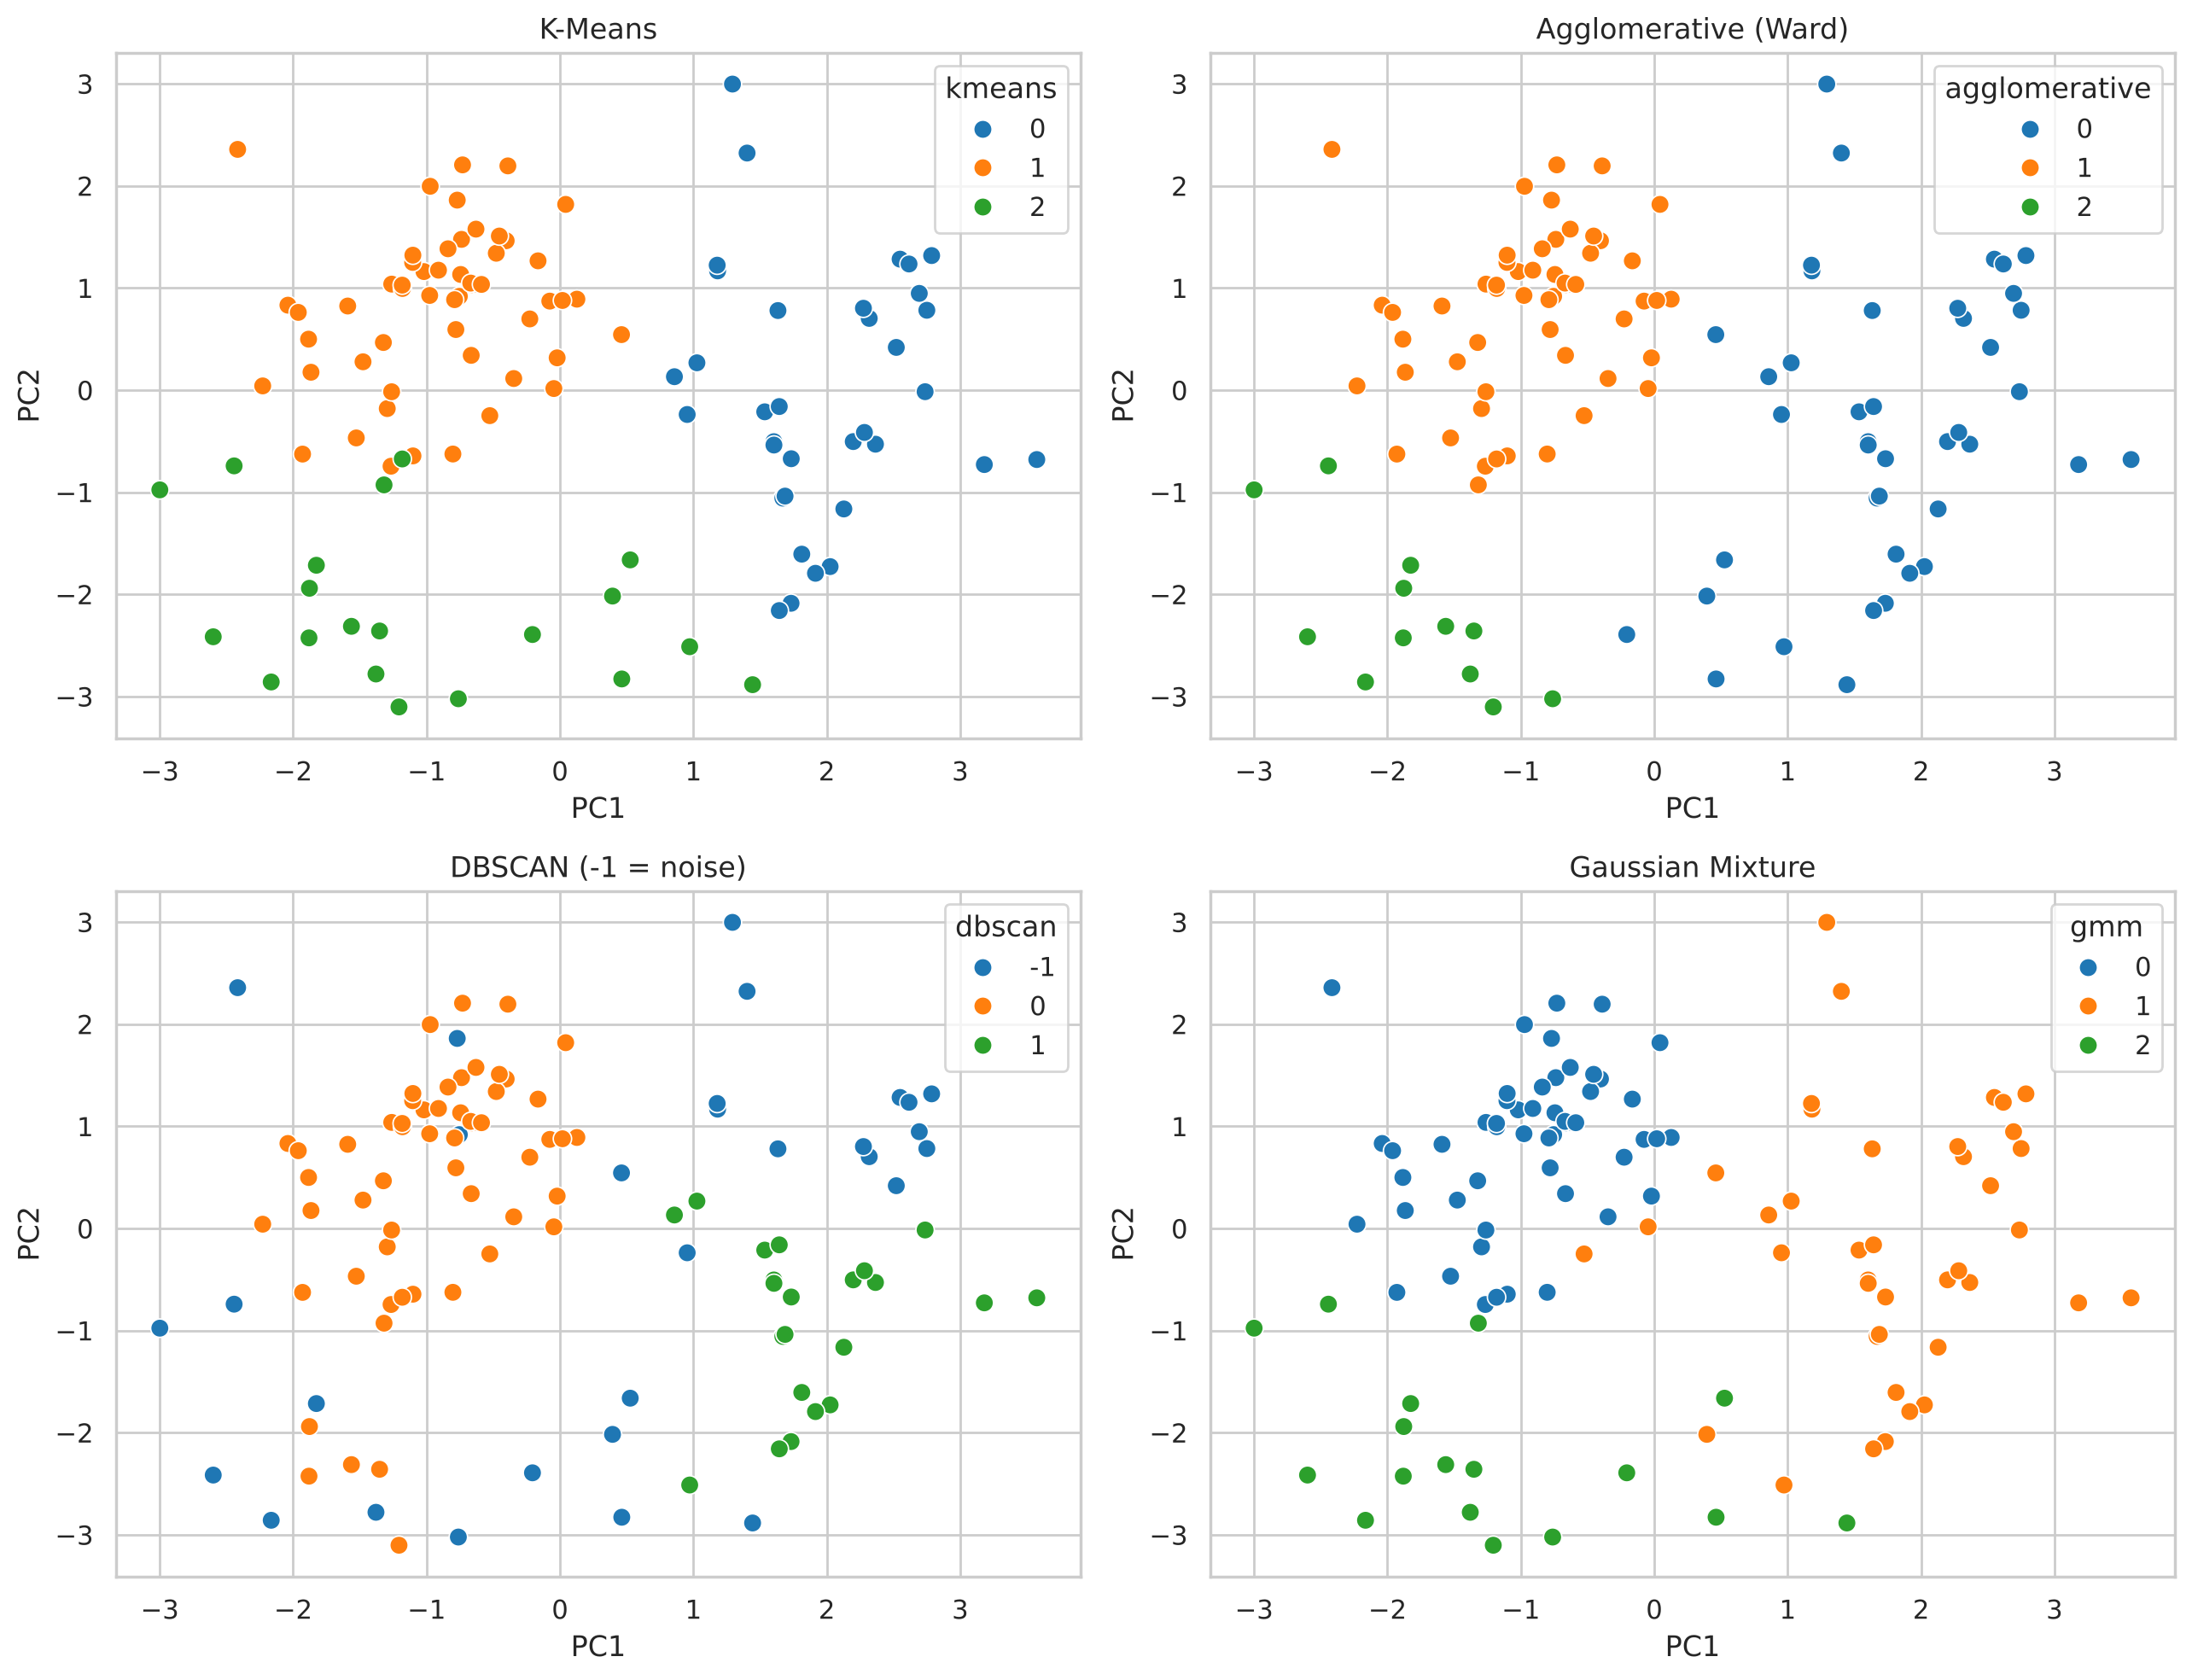

,PC1,PC2
mean_log_price,-0.02,-0.55
cv_price,0.49,0.35
log_p95_p5,0.56,0.26
mean_spread,-0.15,0.56
mean_log_arrival,-0.35,0.39
monsoon_uplift,0.54,-0.18
price_arrival_corr,-0.15,0.10


In [13]:
# Reduce the 7 standardised features to 2 principal components for plotting
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X)
features["PC1"], features["PC2"] = pcs[:, 0], pcs[:, 1]
print("Variance explained by PC1 + PC2: %.1f%%" % (100 * pca.explained_variance_ratio_.sum()))

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (title, col) in zip(axes.ravel(), [("K-Means", "kmeans"), ("Agglomerative (Ward)", "agglomerative"),
                                           ("DBSCAN (-1 = noise)", "dbscan"), ("Gaussian Mixture", "gmm")]):
    sns.scatterplot(data=features, x="PC1", y="PC2", hue=col, palette="tab10", s=60, ax=ax, legend="full")
    ax.set_title(title)
plt.tight_layout(); plt.show()

# Which original features drive each principal component?
loadings = pd.DataFrame(pca.components_.T, index=FEATURE_COLS, columns=["PC1", "PC2"])
display(loadings.round(2))

### 8.13 Silhouette plot for the final K-Means model

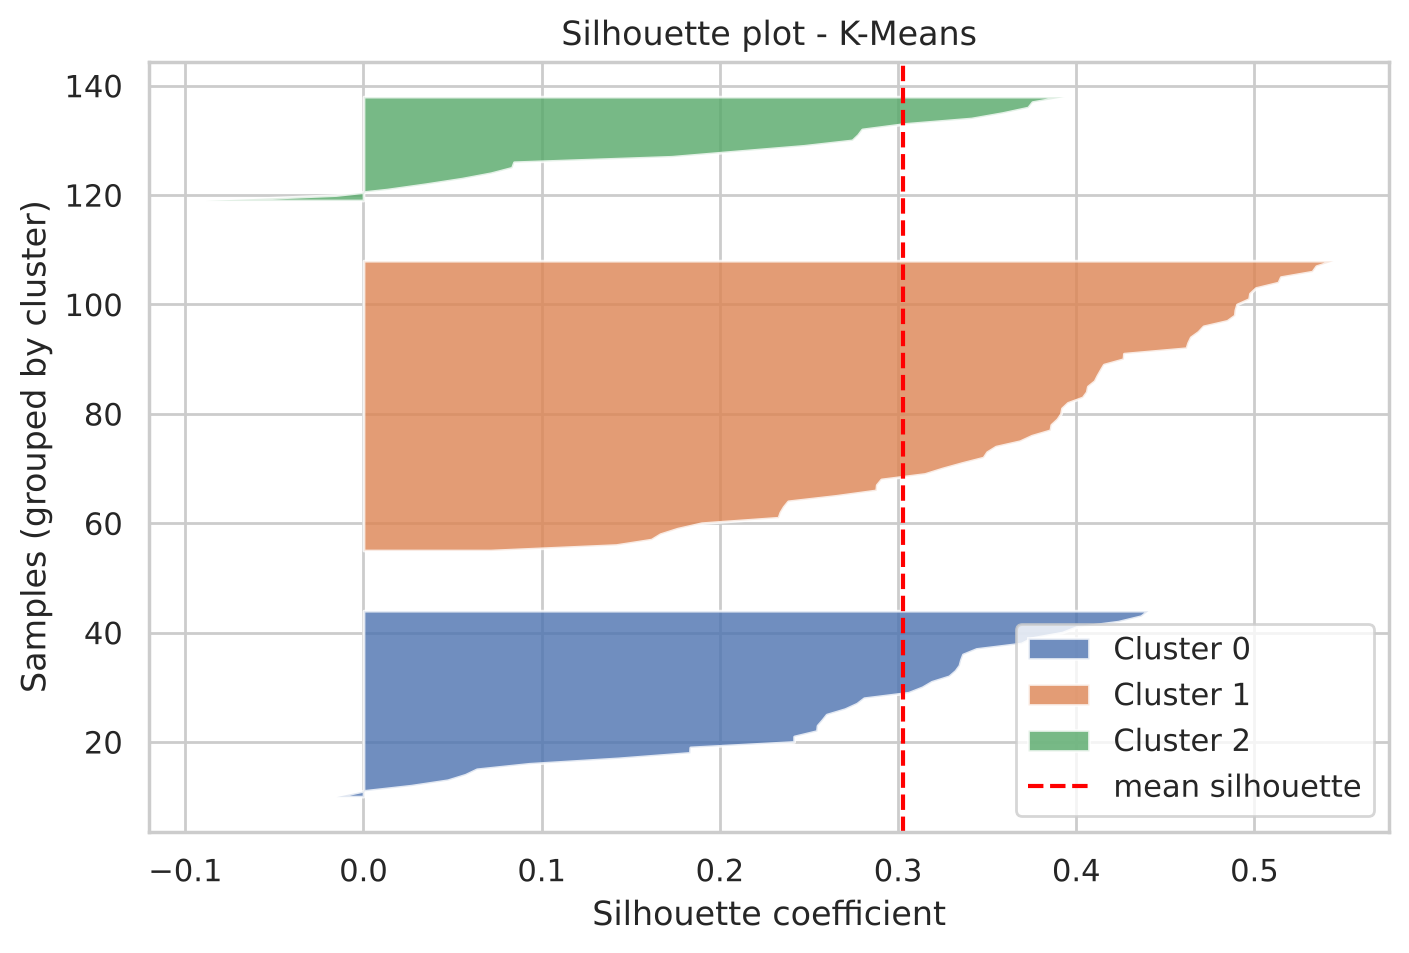

Samples with negative silhouette: 4 of 109


In [14]:
# Per-sample silhouette values show how well each point fits its cluster;
# negative values indicate points that probably sit in the wrong cluster.
sil_vals = silhouette_samples(X, features.kmeans)
fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 10
for c in sorted(features.kmeans.unique()):
    vals = np.sort(sil_vals[features.kmeans == c])
    y_upper = y_lower + len(vals)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, alpha=0.8, label=f"Cluster {c}")
    y_lower = y_upper + 10
ax.axvline(silhouette_score(X, features.kmeans), color="red", linestyle="--", label="mean silhouette")
ax.set_xlabel("Silhouette coefficient"); ax.set_ylabel("Samples (grouped by cluster)")
ax.set_title("Silhouette plot - K-Means"); ax.legend(); plt.show()

print("Samples with negative silhouette: %d of %d" % ((sil_vals < 0).sum(), len(sil_vals)))

### 8.14 Profile and interpret the clusters

,mean_log_price,cv_price,log_p95_p5,mean_spread,mean_log_arrival,monsoon_uplift,price_arrival_corr,n_pairs,mean_price_Rs_qtl,mean_arrival_t
kmeans,,,,,,,,,,
0,6.68,0.76,2.36,0.70,2.29,1.70,-0.14,35,798.21,8.87
1,6.69,0.67,1.81,0.96,5.44,0.91,-0.05,54,805.40,229.51
2,7.01,0.50,1.46,0.47,2.54,1.17,-0.14,20,1104.62,11.66


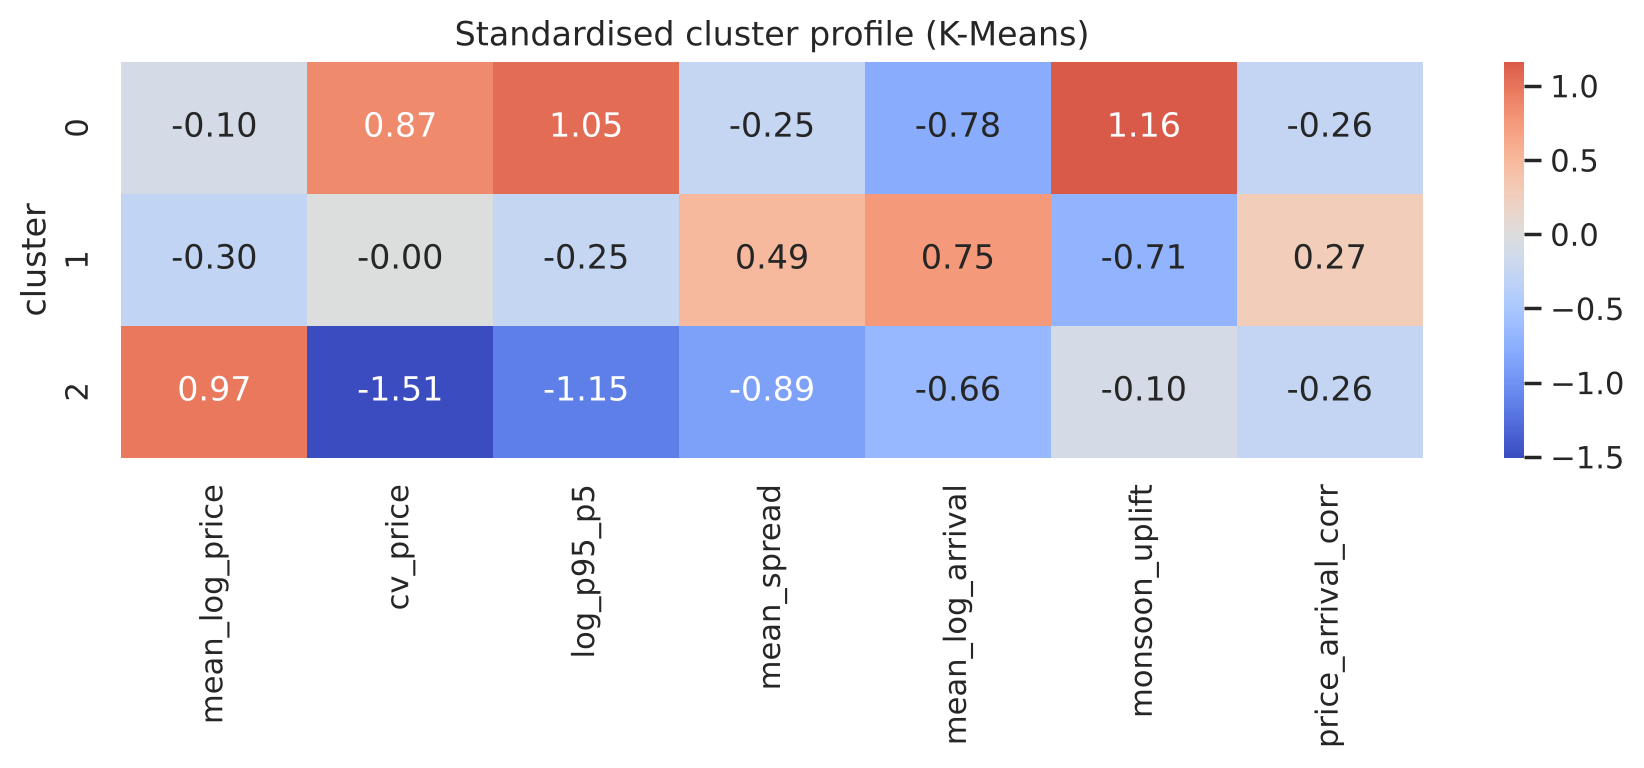

Commodity composition of each cluster (counts):


commodity_name,Onion,Tomato
kmeans,,
0,1,34
1,53,1
2,13,7


Largest mandis (by mean arrivals) in each cluster:
  Cluster 0: Pimpalgaon (Tomato), Junnar(Narayangaon) (Tomato), Pune (Tomato), Nasik (Tomato), Lasalgaon (Tomato)
  Cluster 1: Ahmednagar (Onion), Newasa(Ghodegaon) (Onion), Solapur (Onion), Vashi New Mumbai (Onion), Pune (Onion)
  Cluster 2: Panvel (Tomato), Dindori (Onion), Pathardi (Onion), Satara (Onion), Chandrapur(Ganjwad) (Onion)


In [15]:
# Mean of each (un-scaled) feature per cluster of the final model, plus cluster size
profile = features.groupby(FINAL_COL)[FEATURE_COLS].mean()
profile["n_pairs"] = features.groupby(FINAL_COL).size()
profile["mean_price_Rs_qtl"] = np.exp(profile.mean_log_price)       # convert log price back to Rs/quintal
profile["mean_arrival_t"] = np.expm1(profile.mean_log_arrival)       # convert log arrivals back to tonnes
display(profile.round(2))

# Heatmap of standardised cluster centres: red = above average, blue = below average
centres = pd.DataFrame(X, columns=FEATURE_COLS).groupby(features[FINAL_COL].values).mean()
plt.figure(figsize=(9, 4))
sns.heatmap(centres, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title(f"Standardised cluster profile ({FINAL})"); plt.ylabel("cluster")
plt.tight_layout(); plt.show()

# How do the clusters split across commodities?
print("Commodity composition of each cluster (counts):")
display(pd.crosstab(features[FINAL_COL], features.commodity_name))

# Example mandis in each cluster, ordered by size of arrivals
print("Largest mandis (by mean arrivals) in each cluster:")
for c, g in features.groupby(FINAL_COL):
    top = g.sort_values("mean_log_arrival", ascending=False).head(5)
    print(f"  Cluster {c}: " + ", ".join(f"{m} ({cm})" for m, cm in zip(top.market_name, top.commodity_name)))

### 8.15 Cluster behaviour over time (link to price forecasting)
The 2016-2018 period is the continuous part of the collected history, so it is used for this check.

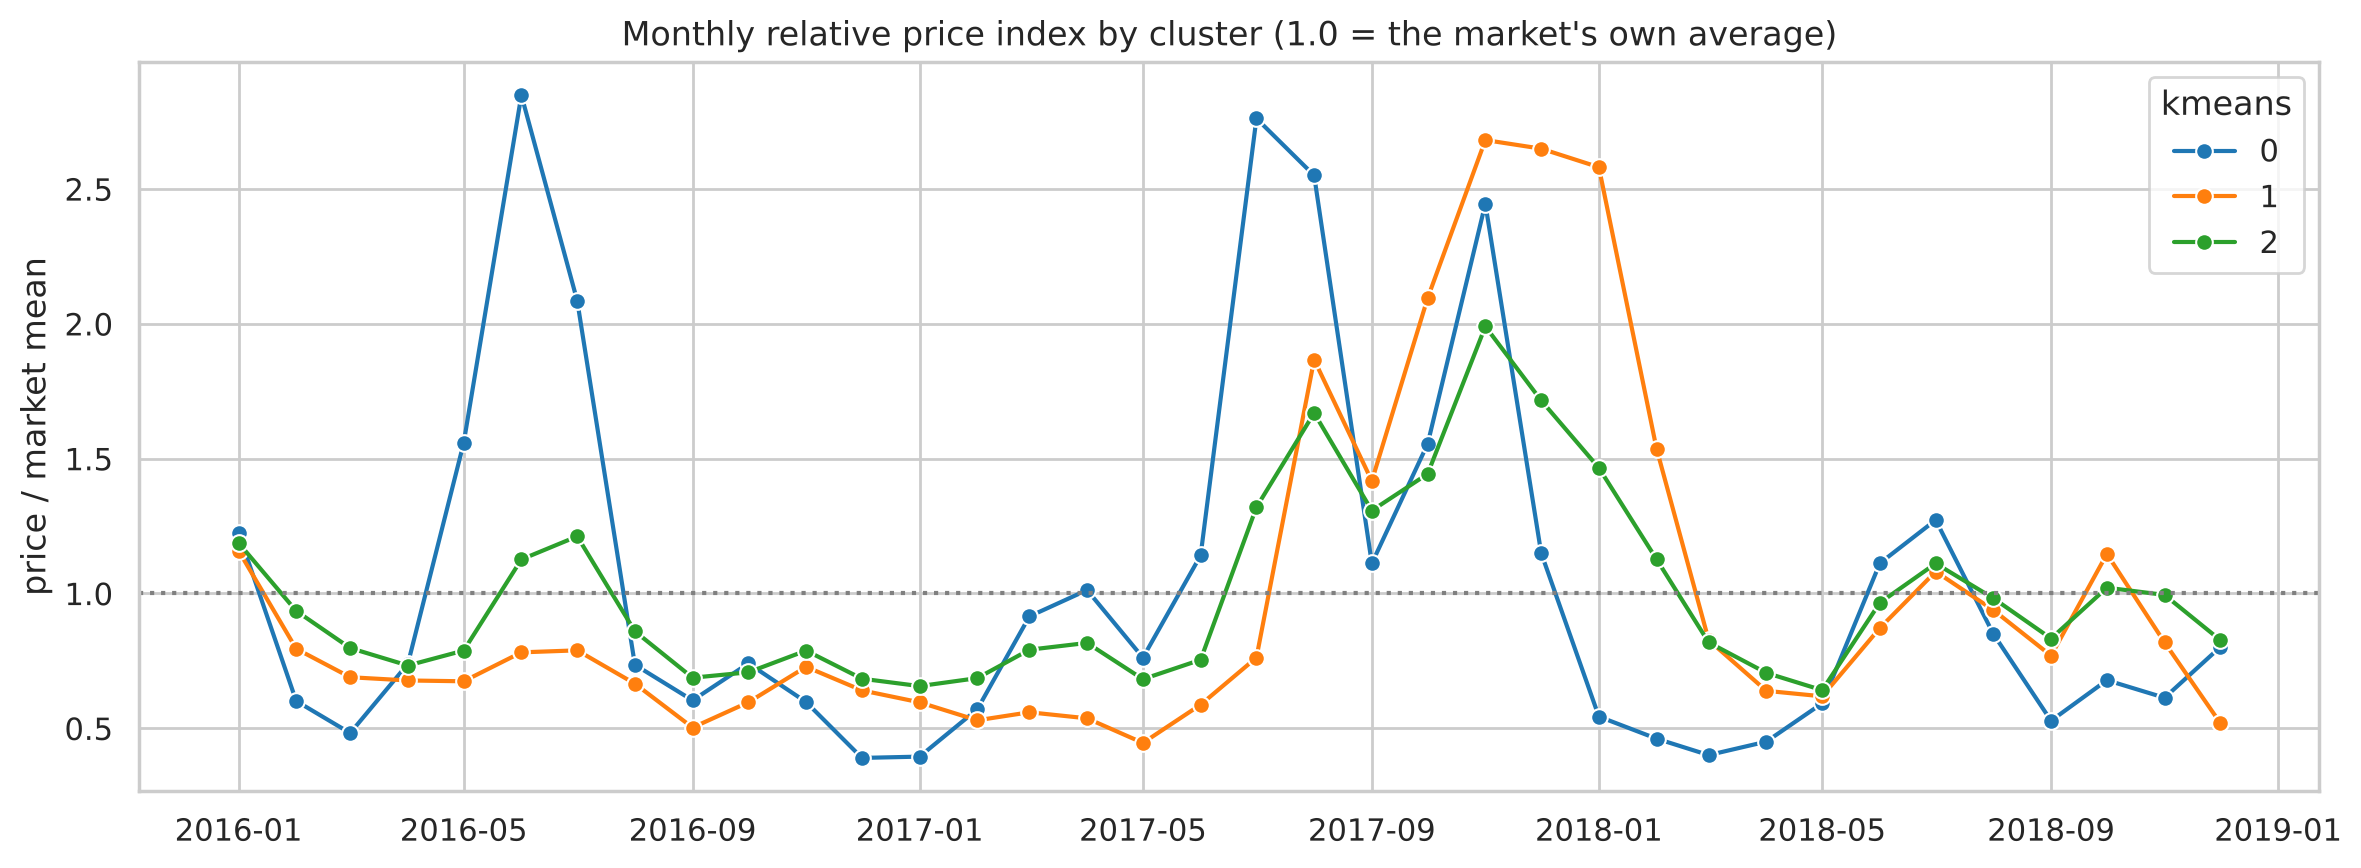

In [16]:
# Average monthly price per cluster to confirm that the clusters really behave differently over time.
# Each price series is divided by its own mean first, so clusters are comparable on a common scale.
tmp = daily.merge(features[["commodity_name", "market_name", FINAL_COL]], on=["commodity_name", "market_name"])
tmp["price_index"] = tmp.modal / tmp.groupby(["commodity_name", "market_name"]).modal.transform("mean")

# The collected history is continuous for 2016-2018; after that only a small snapshot of Nov 2026
# exists (no data for 2019-2025). Joining the two with a line would be misleading, so we plot 2016-2018 only.
tmp = tmp[tmp.observation_date < "2019-01-01"]
monthly = (tmp.set_index("observation_date").groupby(FINAL_COL).price_index.resample("MS").mean()
              .reset_index().dropna())

plt.figure(figsize=(12, 4.5))
sns.lineplot(data=monthly, x="observation_date", y="price_index", hue=FINAL_COL, palette="tab10", marker="o")
plt.axhline(1, color="grey", linestyle=":")
plt.title("Monthly relative price index by cluster (1.0 = the market's own average)")
plt.ylabel("price / market mean"); plt.xlabel("")
plt.tight_layout(); plt.show()

### 8.16 Household affordability context (HCES)
Clustering tells us *where* prices are risky; the HCES survey tells us *how much it matters* to households. The cell below reads the household expenditure file and shows the share of the food budget spent on vegetables, the group that onion and tomato belong to.

In [17]:
hces = pd.read_csv(os.path.join(DATA_DIR, "household_expenditure.csv"))

# NOTE: the item-group rows from Statement 5 in this CSV look misaligned (MPCE and share columns
# are mixed up between Rural and Urban), so they are NOT used here. Only the clean Statement 1
# (food vs non-food share) and Statement 8 (state-wise MPCE) rows are used.
food_share = hces[(hces.indicator_name == "Food vs Non-Food MPCE & Share") & (hces.item_group == "Food")]
display(food_share[["survey_year", "geography", "sector", "mpce_value_rs", "share_percentage"]])

maha = hces[(hces.indicator_name == "State-wise Average MPCE") & (hces.geography == "Maharashtra")]
display(maha[["geography", "sector", "mpce_value_rs"]])

,survey_year,geography,sector,mpce_value_rs,share_percentage
0,2022-23,All India,Rural,1750.0,46.0
1,2022-23,All India,Urban,2530.0,39.0


,geography,sector,mpce_value_rs
106,Maharashtra,Rural,4010.0
107,Maharashtra,Urban,6657.0


## 9. Results Analysis

**Data used:** 109 (mandi, commodity) price series from Maharashtra (67 onion, 42 tomato), each with at least 150 daily observations, described by 7 behavioural features. After cleaning, 744 extreme price entries were removed.

**Choosing k.** Silhouette peaked at k = 3 (0.302) among the k values with no tiny clusters, and the Davies-Bouldin index was also lowest at k = 3 (1.232). A first attempt without winsorizing the features gave k = 5 as "best", but two of those clusters contained a single mandi each (pure outliers), so winsorizing at the 2.5th-97.5th percentile and a minimum cluster size of 5 were added to obtain meaningful segments.

**Algorithm comparison**

| Algorithm | Clusters | Noise points | Silhouette (higher better) | Davies-Bouldin (lower better) | Calinski-Harabasz (higher better) |
|---|---|---|---|---|---|
| K-Means | 3 | 0 | 0.303 | 1.235 | 41.99 |
| Agglomerative (Ward) | 3 | 0 | 0.300 | 1.226 | 39.44 |
| Gaussian Mixture | 3 | 0 | 0.296 | 1.240 | 40.33 |
| DBSCAN | 2 | 30 | 0.392 | 1.042 | 49.33 |

- K-Means, Agglomerative and GMM give almost identical scores, which shows that the 3-group structure is **stable and not an artefact of one algorithm**.
- DBSCAN's higher scores are **not directly comparable**: it labelled 30 of 109 series (27.5%) as noise and was scored only on the remaining 79 points, which are the easiest to separate. It is useful as a confirmation that two dense groups (mostly onion and mostly tomato series) exist, and that about a quarter of the markets sit "in between".
- The silhouette values of about 0.30 indicate **weak to moderate** cluster structure: groups are real but overlap, which is expected for markets whose behaviour changes gradually. Only 4 of 109 points had a negative silhouette (possible mis-assignments).
- PCA with two components explains 63.5% of the variance; the plots show three recognisable regions, with some overlap at the boundaries.

**Cluster interpretation (K-Means, k = 3)**

| Cluster | Size | Composition | Mean price (Rs/qtl) | Volatility (CV) | Price-range ratio (log p95/p5) | Mean arrivals (t/day) | Monsoon price uplift | Interpretation |
|---|---|---|---|---|---|---|---|---|
| 0 | 35 | 34 tomato, 1 onion | ~798 | 0.76 (highest) | 2.36 (highest) | ~9 | 1.70 | **Volatile, small tomato markets** with strong monsoon price spikes |
| 1 | 54 | 53 onion, 1 tomato | ~805 | 0.67 | 1.81 | ~230 | 0.91 | **Large, high-volume onion hubs** where prices are not higher in monsoon |
| 2 | 20 | 13 onion, 7 tomato | ~1105 (highest) | 0.50 (lowest) | 1.46 (lowest) | ~12 | 1.17 | **Stable, higher-priced, low-volume markets** with narrow intra-day spread |

The monthly price-index plot (2016-2018) supports this: cluster 0 shows sharp tomato spikes in mid-2016 and mid-2017 (up to about 2.8 times the market's own average), the onion-dominated cluster 1 shows a long surge from late 2017 to early 2018, and cluster 2 moves more smoothly with a smaller peak (about 2.0).

**Limitations.** (i) The collected history is continuous only for 2016-2018, plus a small snapshot from November 2026, so the segments describe that period. (ii) Cluster membership is strongly related to the commodity (tomato vs onion), so the result partly separates the two crops; the within-commodity differences (cluster 2) are the more informative finding for market-level risk. (iii) Silhouette around 0.3 means the segments should be used as soft groupings, not hard rules.

## 10. Conclusion

- Four clustering algorithms (K-Means, Agglomerative/Ward, DBSCAN and Gaussian Mixture) were implemented on 109 Maharashtra mandi-commodity price series built from the data collected in the previous step of the project.
- Model selection with the elbow method, silhouette score and Davies-Bouldin index pointed to **k = 3**; K-Means, Ward and GMM agreed closely (silhouette about 0.30, Davies-Bouldin about 1.23), while DBSCAN confirmed two dense groups and flagged 27.5% of series as noise.
- The three segments are interpretable: **volatile small tomato markets**, **large stable-volume onion hubs**, and **stable higher-priced low-volume markets**. They differ in volatility, monsoon sensitivity, arrival size and price level, and the monthly price plot confirms they react differently to supply shocks.
- Clustering quality is **moderate (silhouette about 0.3)**, so the clusters are best used as soft risk groups. Data preparation (winsorizing outliers, enforcing a minimum cluster size) mattered more than the choice of algorithm.
- **Use in the project:** the cluster label can be added as a feature, or a separate forecasting model can be trained for each cluster, in the next step (time-series price prediction), and the volatile-tomato cluster is the natural target for early-warning in the household affordability monitor.

---
*Next step in the project:* use the cluster label as an extra input feature (or train one forecasting model per cluster) for the **time-series price prediction models** (e.g. on `model_ready_pune_tomato.csv`), followed by the household affordability index and monitoring dashboard.